In [1]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Flatten, Input
from tensorflow.keras.layers import Conv2D, MaxPooling2D, BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras import utils
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
%matplotlib inline

In [2]:
from numpy.random import seed
seed(2023)
from tensorflow.random import set_seed
set_seed(2023)

from tensorflow.keras.datasets import fashion_mnist

In [3]:
print("Инициализация загрузки датасета Fashion MNIST...")
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

Инициализация загрузки датасета Fashion MNIST...


In [4]:
category_names = ['t-shirt', 'trousers', 'pullover', 'dress', 'coat', 
                  'sandals', 'shirt', 'sneakers', 'bag', 'ankle boots']

In [5]:
print(f"Формат обучающей выборки: {x_train.shape}")
print(f"Формат тестовой выборки: {x_test.shape}")

Формат обучающей выборки: (60000, 28, 28)
Формат тестовой выборки: (10000, 28, 28)


In [6]:
x_train = x_train / 255.0
x_test = x_test / 255.0

In [7]:
y_train_enc = utils.to_categorical(y_train, 10)
y_test_enc = utils.to_categorical(y_test, 10)

In [8]:
RUN_SIMPLE_MLP = True     
RUN_BASIC_CNN = True       
RUN_ADVANCED_CNN = True 

In [9]:
if RUN_SIMPLE_MLP:
    
    x_train_reshaped = x_train.reshape(60000, 784)
    x_test_reshaped = x_test.reshape(10000, 784)
    
    simple_model = Sequential()
    simple_model.add(Input(shape=(784,)))
    simple_model.add(Dense(512, activation='relu'))
    simple_model.add(Dropout(0.4))
    simple_model.add(Dense(256, activation='relu'))
    simple_model.add(Dropout(0.3))
    simple_model.add(Dense(10, activation='softmax'))
    
    simple_model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    
    simple_model.summary()
    
    start_training = time.time()
    training_history_simple = simple_model.fit(
        x_train_reshaped, y_train_enc,
        batch_size=128,
        epochs=30,
        validation_split=0.15,
        verbose=1,
        callbacks=[
            EarlyStopping(patience=4, restore_best_weights=True),
            ReduceLROnPlateau(factor=0.5, patience=2, verbose=1)
        ]
    )
    training_duration_simple = time.time() - start_training
    
    test_score_simple = simple_model.evaluate(x_test_reshaped, y_test_enc, verbose=0)
    print(f"\nТочность на тестовой выборке: {test_score_simple[1]:.4f}")
    print(f"Время обучения: {training_duration_simple/60:.2f} минут")
else:
    print("\nПропуск Модели 1")
    test_score_simple = [0, 0]
    training_history_simple = None
    training_duration_simple = 0

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 512)                 │         401,920 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 256)                 │         131,328 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 10)                  │           2,570 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 535,818 (2.04 MB)

 Trainable params: 535,818 (2.04 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.7852 - loss: 0.5992 - val_accuracy: 0.8496 - val_loss: 0.4108 - learning_rate: 0.0010
Epoch 2/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.8425 - loss: 0.4321 - val_accuracy: 0.8656 - val_loss: 0.3722 - learning_rate: 0.0010
Epoch 3/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.8539 - loss: 0.3998 - val_accuracy: 0.8713 - val_loss: 0.3518 - learning_rate: 0.0010
Epoch 4/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.8623 - loss: 0.3731 - val_accuracy: 0.8723 - val_loss: 0.3510 - learning_rate: 0.0010
Epoch 5/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.8665 - loss: 0.3586 - val_accuracy: 0.8753 - val_loss: 0.3404 - learning_rate: 0.0010
Epoch 6/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.8731 - loss: 0.3440 - val_accuracy: 0.8767 - val_loss: 0.3382 - learning_rate: 0.0010
Epoch 7/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.8766 - loss: 0.

In [10]:
if RUN_BASIC_CNN:
    x_train_conv = x_train.reshape(60000, 28, 28, 1)
    x_test_conv = x_test.reshape(10000, 28, 28, 1)
    
    basic_cnn = Sequential()
    basic_cnn.add(Input(shape=(28, 28, 1)))
    basic_cnn.add(Conv2D(32, (3, 3), activation='relu'))
    basic_cnn.add(MaxPooling2D(2, 2))
    basic_cnn.add(Dropout(0.2))
    
    basic_cnn.add(Conv2D(64, (3, 3), activation='relu'))
    basic_cnn.add(MaxPooling2D(2, 2))
    basic_cnn.add(Dropout(0.3))
    
    basic_cnn.add(Conv2D(128, (3, 3), activation='relu'))
    basic_cnn.add(MaxPooling2D(2, 2))
    basic_cnn.add(Dropout(0.3))
    
    basic_cnn.add(Flatten())
    basic_cnn.add(Dense(256, activation='relu'))
    basic_cnn.add(Dropout(0.4))
    basic_cnn.add(Dense(10, activation='softmax'))
    
    basic_cnn.compile(
        optimizer=Adam(learning_rate=0.001),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    
    basic_cnn.summary()
    
    start_training = time.time()
    training_history_cnn = basic_cnn.fit(
        x_train_conv, y_train_enc,
        batch_size=64,
        epochs=25,
        validation_split=0.15,
        verbose=1,
        callbacks=[
            EarlyStopping(patience=4, restore_best_weights=True),
            ReduceLROnPlateau(factor=0.5, patience=2, verbose=0)
        ]
    )
    training_duration_cnn = time.time() - start_training
    
    test_score_cnn = basic_cnn.evaluate(x_test_conv, y_test_enc, verbose=0)
    print(f"\nТочность на тестовой выборке: {test_score_cnn[1]:.4f}")
    print(f"Время обучения: {training_duration_cnn/60:.2f} минут")
else:
    print("\nПропуск Модели 2")
    test_score_cnn = [0, 0]
    training_history_cnn = None
    training_duration_cnn = 0

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 11, 11, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_3 (Dropout)                  │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 3, 3, 128)           │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 1, 1, 128)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_4 (Dropout)                  │ (None, 1, 1, 128)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 256)                 │          33,024 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_5 (Dropout)                  │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 10)                  │           2,570 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 128,266 (501.04 KB)

 Trainable params: 128,266 (501.04 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/25
797/797 ━━━━━━━━━━━━━━━━━━━━ 17s 18ms/step - accuracy: 0.6959 - loss: 0.8107 - val_accuracy: 0.7994 - val_loss: 0.5373 - learning_rate: 0.0010
Epoch 2/25
797/797 ━━━━━━━━━━━━━━━━━━━━ 14s 17ms/step - accuracy: 0.8013 - loss: 0.5466 - val_accuracy: 0.8426 - val_loss: 0.4325 - learning_rate: 0.0010
Epoch 3/25
797/797 ━━━━━━━━━━━━━━━━━━━━ 13s 16ms/step - accuracy: 0.8258 - loss: 0.4753 - val_accuracy: 0.8520 - val_loss: 0.4080 - learning_rate: 0.0010
Epoch 4/25
797/797 ━━━━━━━━━━━━━━━━━━━━ 13s 16ms/step - accuracy: 0.8413 - loss: 0.4376 - val_accuracy: 0.8638 - val_loss: 0.3655 - learning_rate: 0.0010
Epoch 5/25
797/797 ━━━━━━━━━━━━━━━━━━━━ 13s 16ms/step - accuracy: 0.8509 - loss: 0.4067 - val_accuracy: 0.8728 - val_loss: 0.3447 - learning_rate: 0.0010
Epoch 6/25
797/797 ━━━━━━━━━━━━━━━━━━━━ 13s 16ms/step - accuracy: 0.8571 - loss: 0.3908 - val_accuracy: 0.8774 - val_loss: 0.3333 - learning_rate: 0.0010
Epoch 7/25
797/797 ━━━━━━━━━━━━━━━━━━━━ 13s 16ms/step - accuracy: 0.8606 - l

In [11]:
if RUN_ADVANCED_CNN:

    if not RUN_BASIC_CNN:
        x_train_conv = x_train.reshape(60000, 28, 28, 1)
        x_test_conv = x_test.reshape(10000, 28, 28, 1)
    

    optimized_cnn = Sequential()
    optimized_cnn.add(Input(shape=(28, 28, 1)))
    

    optimized_cnn.add(Conv2D(32, (3, 3), padding='same', activation='relu'))
    optimized_cnn.add(BatchNormalization())
    optimized_cnn.add(Conv2D(32, (3, 3), padding='same', activation='relu'))
    optimized_cnn.add(BatchNormalization())
    optimized_cnn.add(MaxPooling2D(2, 2))
    optimized_cnn.add(Dropout(0.25))
    

    optimized_cnn.add(Conv2D(64, (3, 3), padding='same', activation='relu'))
    optimized_cnn.add(BatchNormalization())
    optimized_cnn.add(Conv2D(64, (3, 3), padding='same', activation='relu'))
    optimized_cnn.add(BatchNormalization())
    optimized_cnn.add(MaxPooling2D(2, 2))
    optimized_cnn.add(Dropout(0.3))
    

    optimized_cnn.add(Flatten())
    optimized_cnn.add(Dense(128, activation='relu'))
    optimized_cnn.add(BatchNormalization())
    optimized_cnn.add(Dropout(0.4))
    optimized_cnn.add(Dense(10, activation='softmax'))
    

    optimized_cnn.compile(
        optimizer=Adam(learning_rate=0.001),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    

    optimized_cnn.summary()
    

    start_training = time.time()
    training_history_advanced = optimized_cnn.fit(
        x_train_conv, y_train_enc,
        batch_size=128,  
        epochs=25,       
        validation_split=0.15,
        verbose=1,
        callbacks=[
            EarlyStopping(patience=5, restore_best_weights=True, monitor='val_loss'),
            ReduceLROnPlateau(factor=0.5, patience=2, verbose=1, monitor='val_loss')
        ]
    )
    training_duration_advanced = time.time() - start_training
    
    # Оценка точности
    test_score_advanced = optimized_cnn.evaluate(x_test_conv, y_test_enc, verbose=0)
    print(f"\nТочность на тестовой выборке: {test_score_advanced[1]:.4f}")
    print(f"Время обучения: {training_duration_advanced/60:.2f} минут")
else:
    print("\nПропуск Модели 3")
    test_score_advanced = [0, 0]
    training_history_advanced = None
    training_duration_advanced = 0

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)                    │ (None, 28, 28, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 28, 28, 32)          │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_4 (Conv2D)                    │ (None, 28, 28, 32)          │           9,248 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 28, 28, 32)          │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 14, 14, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_6 (Dropout)                  │ (None, 14, 14, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_5 (Conv2D)                    │ (None, 14, 14, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 14, 14, 64)          │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_6 (Conv2D)                    │ (None, 14, 14, 64)          │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_3                │ (None, 14, 14, 64)          │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_4 (MaxPooling2D)       │ (None, 7, 7, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_7 (Dropout)                  │ (None, 7, 7, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 3136)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 128)                 │         401,536 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_4                │ (None, 128)                 │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_8 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 469,098 (1.79 MB)

 Trainable params: 468,458 (1.79 MB)

 Non-trainable params: 640 (2.50 KB)

Epoch 1/25
399/399 ━━━━━━━━━━━━━━━━━━━━ 59s 136ms/step - accuracy: 0.8291 - loss: 0.4783 - val_accuracy: 0.6983 - val_loss: 0.9910 - learning_rate: 0.0010
Epoch 2/25
399/399 ━━━━━━━━━━━━━━━━━━━━ 54s 134ms/step - accuracy: 0.8875 - loss: 0.3097 - val_accuracy: 0.9096 - val_loss: 0.2508 - learning_rate: 0.0010
Epoch 3/25
399/399 ━━━━━━━━━━━━━━━━━━━━ 83s 136ms/step - accuracy: 0.9024 - loss: 0.2661 - val_accuracy: 0.9177 - val_loss: 0.2268 - learning_rate: 0.0010
Epoch 4/25
399/399 ━━━━━━━━━━━━━━━━━━━━ 54s 134ms/step - accuracy: 0.9135 - loss: 0.2386 - val_accuracy: 0.9242 - val_loss: 0.2150 - learning_rate: 0.0010
Epoch 5/25
399/399 ━━━━━━━━━━━━━━━━━━━━ 54s 135ms/step - accuracy: 0.9197 - loss: 0.2212 - val_accuracy: 0.9251 - val_loss: 0.2086 - learning_rate: 0.0010
Epoch 6/25
399/399 ━━━━━━━━━━━━━━━━━━━━ 54s 135ms/step - accuracy: 0.9226 - loss: 0.2092 - val_accuracy: 0.9003 - val_loss: 0.2767 - learning_rate: 0.0010
Epoch 7/25
399/399 ━━━━━━━━━━━━━━━━━━━━ 54s 134ms/step - accuracy: 0.9

In [12]:
all_models_data = []
if RUN_SIMPLE_MLP:
    all_models_data.append(('Простая MLP', test_score_simple[1], training_duration_simple/60))
if RUN_BASIC_CNN:
    all_models_data.append(('Базовая CNN', test_score_cnn[1], training_duration_cnn/60))
if RUN_ADVANCED_CNN:
    all_models_data.append(('Продвинутая CNN', test_score_advanced[1], training_duration_advanced/60))

if all_models_data:
    comparison_df = pd.DataFrame(all_models_data, columns=['Архитектура', 'Точность', 'Время (мин)'])
    comparison_df = comparison_df.sort_values('Точность', ascending=False)
    print(comparison_df.to_string(index=False))
    
    best_accuracy = max(model[1] for model in all_models_data)
    if best_accuracy >= 0.90:
        print(f"\n!!! ПОЗДРАВЛЯЕМ! Цель достигнута. Наивысшая точность: {best_accuracy:.4f} !!!")
    else:
        print(f"\n!!! Внимание! Лучшая точность: {best_accuracy:.4f}, что меньше требуемых 0.90 !!!")
        print("Рекомендуется увеличить количество эпох обучения или оптимизировать архитектуру сети.")
else:
    print("Не выполнено ни одной модели для сравнения")


    Архитектура  Точность  Время (мин)
Продвинутая CNN    0.9358    20.328533
    Базовая CNN    0.8960     5.449581
    Простая MLP    0.8914     1.713725

!!! ПОЗДРАВЛЯЕМ! Цель достигнута. Наивысшая точность: 0.9358 !!!


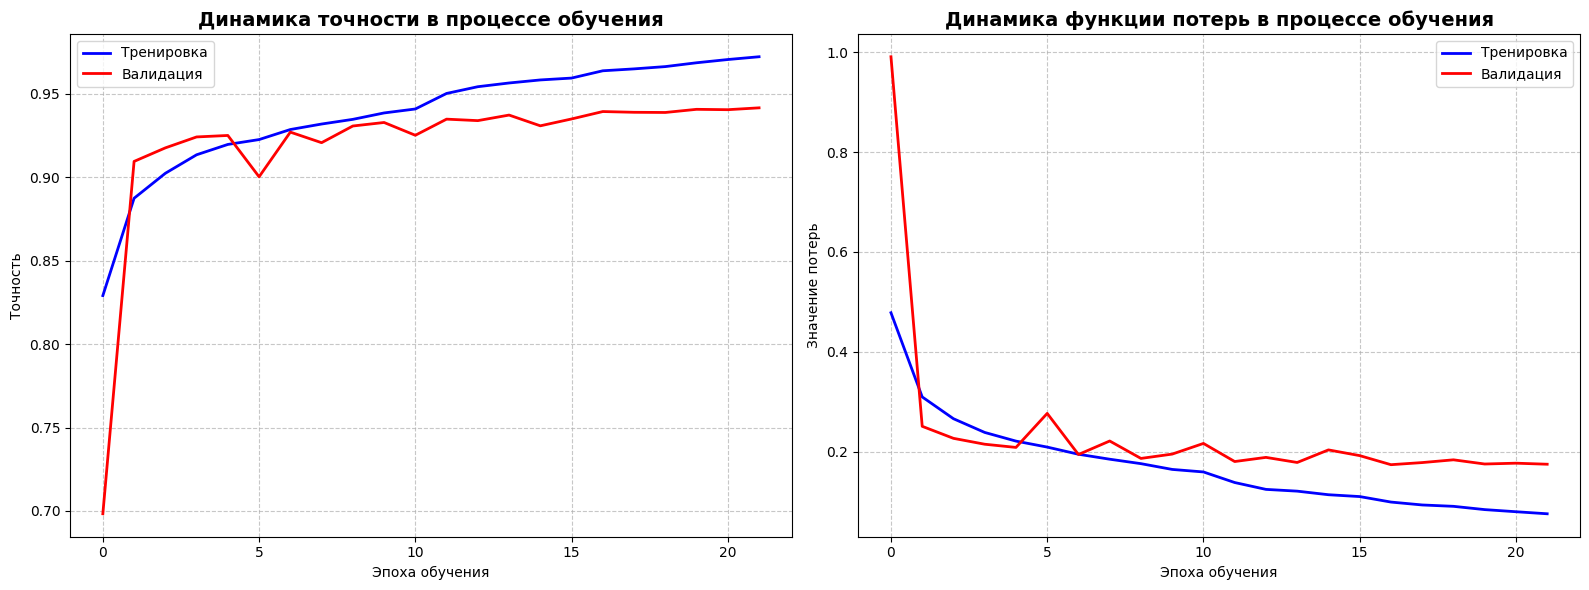

In [13]:
if all_models_data:
    training_histories = []
    if RUN_SIMPLE_MLP and training_history_simple:
        training_histories.append(training_history_simple)
    if RUN_BASIC_CNN and training_history_cnn:
        training_histories.append(training_history_cnn)
    if RUN_ADVANCED_CNN and training_history_advanced:
        training_histories.append(training_history_advanced)
    
    if training_histories:
        model_accuracies = [test_score_simple[1] if RUN_SIMPLE_MLP else 0, 
                          test_score_cnn[1] if RUN_BASIC_CNN else 0,
                          test_score_advanced[1] if RUN_ADVANCED_CNN else 0]
        best_model_index = np.argmax(model_accuracies)
        best_history = training_histories[min(best_model_index, len(training_histories)-1)]
        
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
        
        ax1.plot(best_history.history['accuracy'], 'b-', linewidth=2, label='Тренировка')
        ax1.plot(best_history.history['val_accuracy'], 'r-', linewidth=2, label='Валидация')
        ax1.set_title('Динамика точности в процессе обучения', fontsize=14, fontweight='bold')
        ax1.set_xlabel('Эпоха обучения')
        ax1.set_ylabel('Точность')
        ax1.legend()
        ax1.grid(True, linestyle='--', alpha=0.7)
        
        ax2.plot(best_history.history['loss'], 'b-', linewidth=2, label='Тренировка')
        ax2.plot(best_history.history['val_loss'], 'r-', linewidth=2, label='Валидация')
        ax2.set_title('Динамика функции потерь в процессе обучения', fontsize=14, fontweight='bold')
        ax2.set_xlabel('Эпоха обучения')
        ax2.set_ylabel('Значение потерь')
        ax2.legend()
        ax2.grid(True, linestyle='--', alpha=0.7)
        
        plt.tight_layout()
        plt.show()


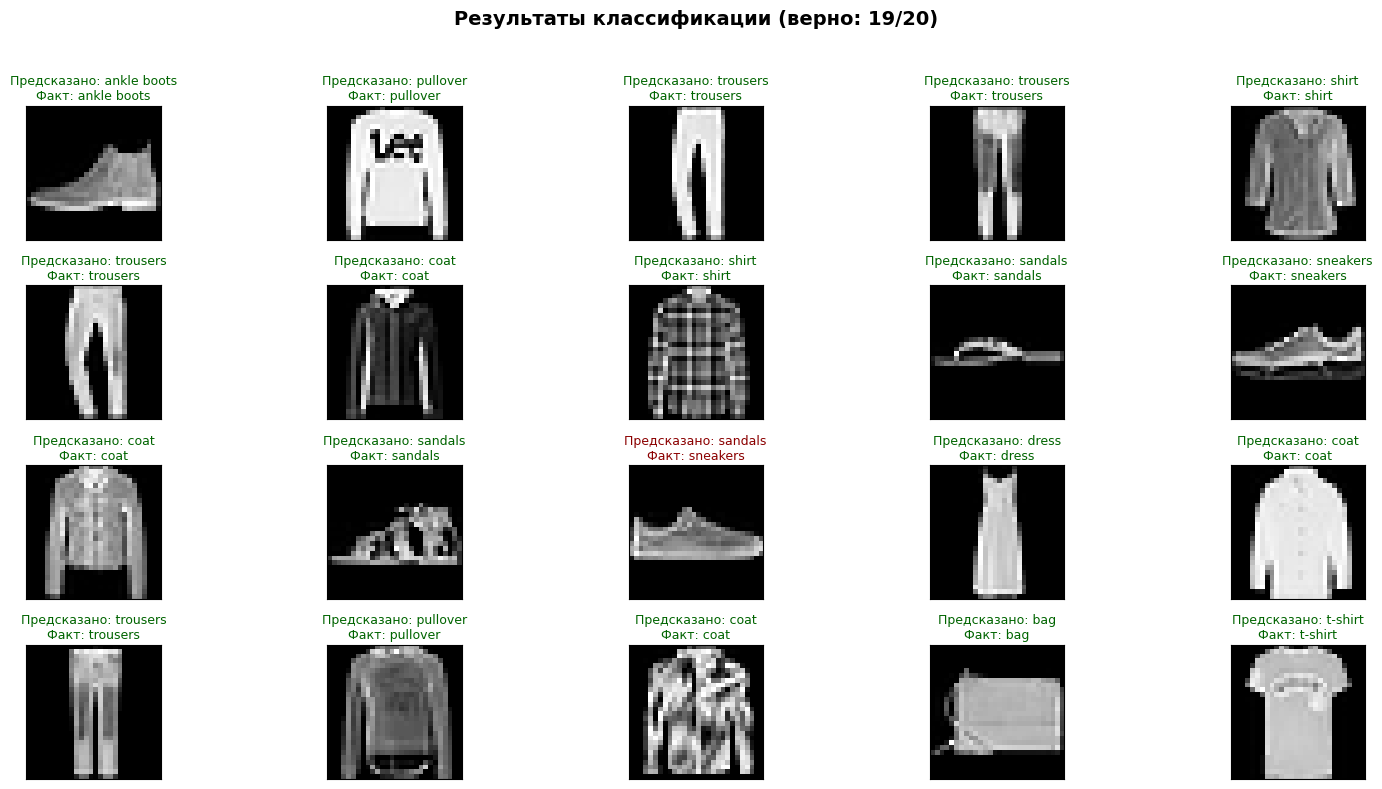

In [15]:
if all_models_data:

    model_collection = []
    test_input_collection = []
    if RUN_SIMPLE_MLP:
        model_collection.append(simple_model)
        test_input_collection.append(x_test_reshaped)
    if RUN_BASIC_CNN:
        model_collection.append(basic_cnn)
        test_input_collection.append(x_test_conv)
    if RUN_ADVANCED_CNN:
        model_collection.append(optimized_cnn)
        test_input_collection.append(x_test_conv)
    
    model_accuracies = [test_score_simple[1] if RUN_SIMPLE_MLP else 0,
                      test_score_cnn[1] if RUN_BASIC_CNN else 0,
                      test_score_advanced[1] if RUN_ADVANCED_CNN else 0]
    
    best_model_position = np.argmax(model_accuracies)
    best_model_selected = model_collection[best_model_position]
    test_data_for_best = test_input_collection[best_model_position]
    
    predictions_batch = best_model_selected.predict(test_data_for_best[:20], verbose=0)
    predicted_classes = np.argmax(predictions_batch, axis=1)
    
    plt.figure(figsize=(16, 8))
    correct_predictions = 0
    
    for idx in range(20):
        plt.subplot(4, 5, idx+1)
        plt.xticks([])
        plt.yticks([])
        plt.grid(False)
        plt.imshow(x_test[idx], cmap='gray')
        
        predicted_item = category_names[predicted_classes[idx]]
        actual_item = category_names[y_test[idx]]
        
        if predicted_classes[idx] == y_test[idx]:
            text_color = 'darkgreen'
            correct_predictions += 1
        else:
            text_color = 'darkred'
        
        plt.title(f'Предсказано: {predicted_item}\nФакт: {actual_item}', 
                 color=text_color, fontsize=9, pad=4)
    
    plt.suptitle(f'Результаты классификации (верно: {correct_predictions}/20)', 
                fontsize=14, fontweight='bold', y=0.98)
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()
